# ABC Filter Validation on Simulated TGA-SV Data

This notebook validates the ABC particle filter on simulated TGA-SV data using the **true parameter vector**.

The filter only receives the observed returns $y_{1:T}$. The latent variables stored in the simulated dataset are used **only afterwards** to assess filtering quality.

Objectives:
- run the ABC filter with the true parameters;
- inspect likelihood and filter diagnostics;
- monitor particle degeneracy through the ESS;
- compare the filtered latent log-volatility with the true simulated $h_t$;
- inspect the adaptive ABC bandwidth.


## 1. Imports


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# This notebook is intended to live in notebooks/.
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.abc_filter import abc_filter


## 2. Load simulated data

The ABC filter must only observe the return series

$$
y_1,\ldots,y_T.
$$

The columns `h`, `sigma`, `epsilon`, `eta`, and `f_epsilon` are latent quantities available only because the dataset was simulated.


In [2]:
data_path = PROJECT_ROOT / "data" / "simulated_tga_sv_normal_T500.csv"

df = pd.read_csv(data_path)
y = df["Return"].to_numpy(dtype=float)

print("T =", len(y))
df.head()


T = 500


,t,h,sigma2,sigma,epsilon,eta,f_epsilon,Return
0,1,2.032523,7.633323,2.762847,-0.384268,-0.035822,0.059380,-1.061675
1,2,2.015430,7.503957,2.739335,1.505382,-0.189925,-0.049681,4.123745
2,3,1.735516,5.671856,2.381566,-0.586593,-0.131709,0.095798,-1.397009
3,4,1.664895,5.285118,2.298938,-0.691560,-0.074353,0.114692,-1.589853
4,5,1.671936,5.322463,2.307046,-0.606306,0.067348,0.099347,-1.398776


## 3. True parameter vector

For validation, the filter is first run with the true parameters used to generate the simulated dataset:

$$
\theta_0=(\mu,\phi,\alpha,\gamma_1,\gamma_2,\sigma_\eta^2)
=(0,0.98,0.07,-0.08,0.10,0.05).
$$

At this stage, the parameters are **not estimated**. The goal is only to validate the filtering procedure.


In [3]:
theta_true = np.array([
    0.0,    # mu
    0.98,   # phi
    0.07,   # alpha
    -0.08,  # gamma1
    0.10,   # gamma2
    0.05,   # sigma_eta^2
])

theta_true


array([ 0.  ,  0.98,  0.07, -0.08,  0.1 ,  0.05])

## 4. Run the ABC particle filter

We start with $N=5000$ particles for validation.

The paper uses much larger particle populations in its numerical experiments, but $N=5000$ is sufficient for a first diagnostic run.


In [4]:
N_PARTICLES = 5000

result = abc_filter(
    y=y,
    theta=theta_true,
    n_particles=N_PARTICLES,
    dist="normal",
    seed=123,
)

print("log-likelihood         :", result["loglik"])
print("average log-likelihood :", result["average_loglik"])


log-likelihood         : -1172.0906500027684
average log-likelihood : -2.3441813000055367


## 5. Filter diagnostics

At each time step, the filter returns:
- the estimated predictive density;
- the log-likelihood increment;
- the adaptive ABC bandwidth;
- the effective sample size (ESS);
- the filtered mean and standard deviation of $h_t$;
- the filtered mean and standard deviation of $h_{t+1}$.


In [5]:
diag = result["diagnostics"]
diag.head()


,t,y,predictive_density,loglik_increment,bandwidth,ess,filtered_h_mean,filtered_h_sd,filtered_h_next_mean,filtered_h_next_sd
0,1,-1.061675,0.147953,-1.910863,1.144539,1331.326874,1.300847,1.154506,1.366296,1.105721
1,2,4.123745,0.026460,-3.632129,0.871792,186.456877,2.190985,0.745069,2.095587,0.740580
2,3,-1.397009,0.119455,-2.124815,1.043078,991.385034,1.930795,0.714622,1.976874,0.721006
3,4,-1.589853,0.122338,-2.100967,0.974017,944.987216,1.823461,0.654106,1.889617,0.645203
4,5,-1.398776,0.129197,-2.046416,0.920804,958.922158,1.783590,0.622933,1.824462,0.635850


In [6]:
diag.describe()


,t,y,predictive_density,loglik_increment,bandwidth,ess,filtered_h_mean,filtered_h_sd,filtered_h_next_mean,filtered_h_next_sd
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,-0.114363,0.122753,-2.344181,0.897024,763.100668,1.733468,0.491605,1.735632,0.517817
std,144.481833,2.825912,0.070061,0.891398,0.377336,313.801812,0.810424,0.067864,0.809556,0.065338
min,1.000000,-16.913173,0.000162,-8.725764,0.345479,1.611178,-0.145672,0.193989,-0.064367,0.220029
25%,125.750000,-1.594239,0.071571,-2.637073,0.614745,542.396748,1.123837,0.451728,1.132374,0.480105
50%,250.500000,-0.029221,0.115576,-2.157831,0.804449,859.503467,1.688684,0.489963,1.680533,0.517652
75%,375.250000,1.478055,0.165926,-1.796216,1.100562,1028.508847,2.283924,0.528323,2.308830,0.554299
max,500.000000,11.741389,0.367841,-1.000103,2.126061,1331.326874,3.831837,1.154506,3.753962,1.105721


## 6. Effective Sample Size

The effective sample size is

$$
\mathrm{ESS}_t=\frac{1}{\sum_{n=1}^N (p_t^{(n)})^2}.
$$

If all normalized particle weights are equal, $\mathrm{ESS}=N$. If almost all the mass is concentrated on one particle, $\mathrm{ESS}\approx1$.


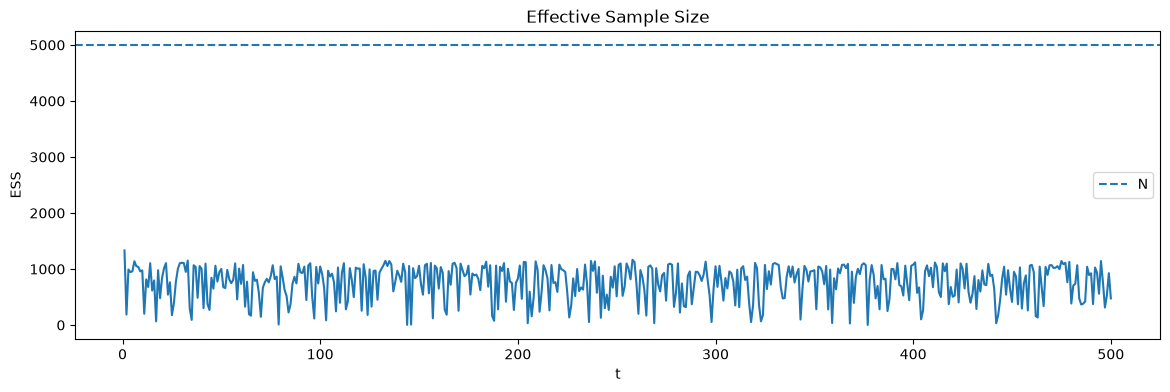

Mean ESS: 763.1006676853607
Min ESS : 1.6111776680876428


In [7]:
plt.figure(figsize=(14, 4))
plt.plot(diag["t"], diag["ess"])
plt.axhline(N_PARTICLES, linestyle="--", label="N")
plt.xlabel("t")
plt.ylabel("ESS")
plt.title("Effective Sample Size")
plt.legend()
plt.show()

print("Mean ESS:", diag["ess"].mean())
print("Min ESS :", diag["ess"].min())


## 7. True vs filtered latent log-volatility

Because the dataset is simulated, the true latent $h_t$ is known.

We compare it with the ABC-filtered posterior mean

$$
E[h_t\mid y_{1:t}].
$$

A perfect point-by-point match is not expected. The goal is to recover the main latent volatility dynamics.


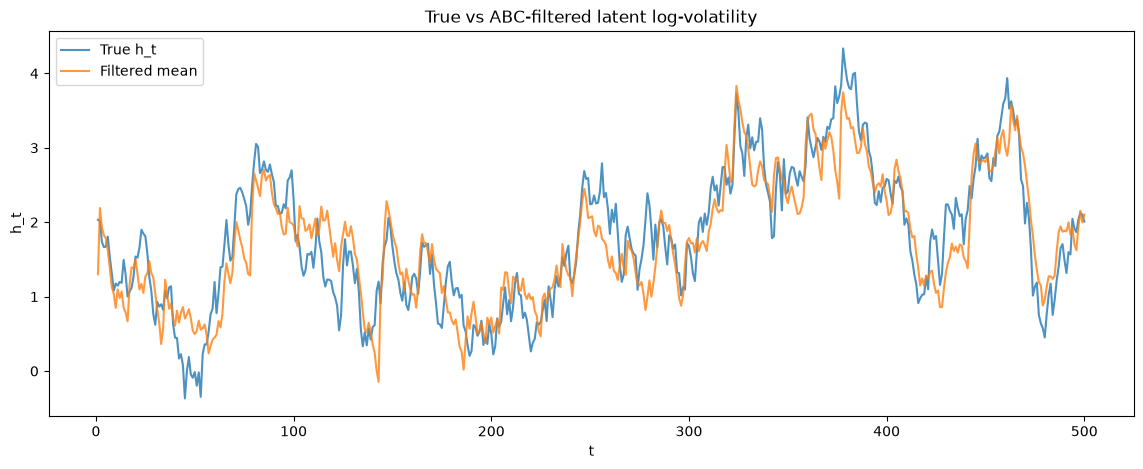

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(df["t"], df["h"], label="True h_t", alpha=0.8)
plt.plot(diag["t"], diag["filtered_h_mean"], label="Filtered mean", alpha=0.8)
plt.xlabel("t")
plt.ylabel("h_t")
plt.title("True vs ABC-filtered latent log-volatility")
plt.legend()
plt.show()


### Filtering error


In [9]:
true_h = df["h"].to_numpy(dtype=float)
filtered_h = diag["filtered_h_mean"].to_numpy(dtype=float)

rmse_h = np.sqrt(np.mean((true_h - filtered_h) ** 2))
corr_h = np.corrcoef(true_h, filtered_h)[0, 1]

print("RMSE h       :", rmse_h)
print("Correlation h:", corr_h)


RMSE h       : 0.4256250326046929
Correlation h: 0.8871431702646642


## 8. Filtering uncertainty

The filtered particle distribution provides a standard deviation for $h_t$ at each time step.

The band below uses $\pm1.96$ filtered standard deviations as a visual diagnostic. It should not automatically be interpreted as an exact Gaussian confidence interval.


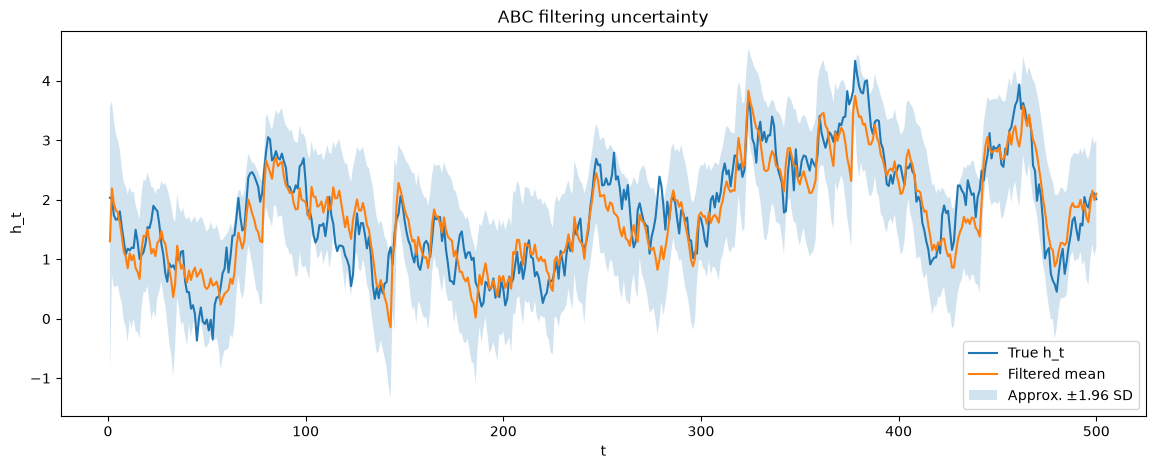

In [10]:
mean_h = diag["filtered_h_mean"].to_numpy()
sd_h = diag["filtered_h_sd"].to_numpy()

lower = mean_h - 1.96 * sd_h
upper = mean_h + 1.96 * sd_h

plt.figure(figsize=(14, 5))
plt.plot(df["t"], true_h, label="True h_t")
plt.plot(diag["t"], mean_h, label="Filtered mean")
plt.fill_between(diag["t"], lower, upper, alpha=0.2, label="Approx. ±1.96 SD")
plt.xlabel("t")
plt.ylabel("h_t")
plt.title("ABC filtering uncertainty")
plt.legend()
plt.show()


## 9. Adaptive ABC bandwidth

The ABC bandwidth controls how strongly pseudo-observations are penalized when they differ from the observed return.

The implementation uses the plug-in bandwidth based on the dispersion of pseudo-observations at each time step.


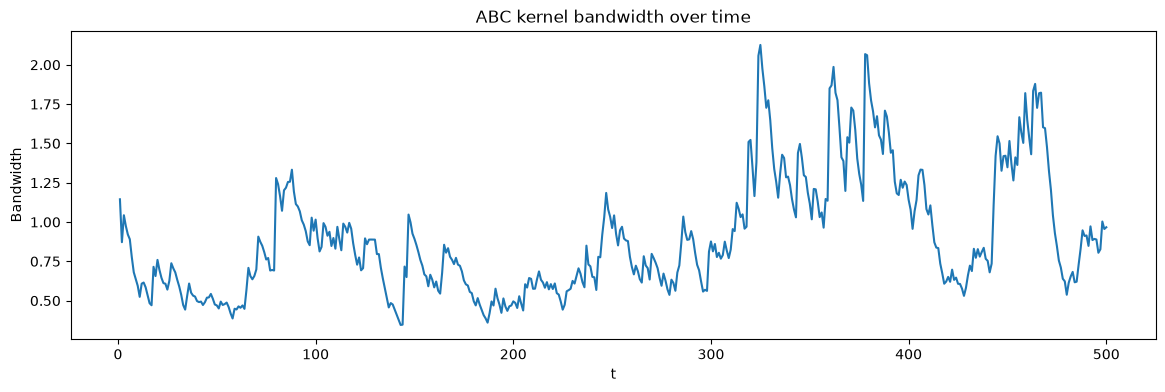

In [11]:
plt.figure(figsize=(14, 4))
plt.plot(diag["t"], diag["bandwidth"])
plt.xlabel("t")
plt.ylabel("Bandwidth")
plt.title("ABC kernel bandwidth over time")
plt.show()


## 10. Likelihood increments

The total estimated log-likelihood is obtained by summing the one-step predictive log-density estimates:

$$
\widehat{\log L}(\theta)=\sum_{t=1}^T \log \widehat p(y_t\mid y_{1:t-1}).
$$


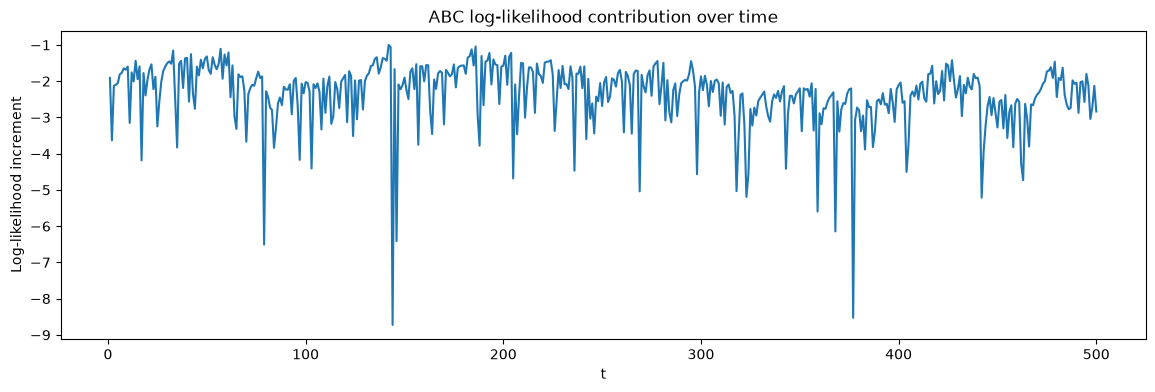

In [12]:
plt.figure(figsize=(14, 4))
plt.plot(diag["t"], diag["loglik_increment"])
plt.xlabel("t")
plt.ylabel("Log-likelihood increment")
plt.title("ABC log-likelihood contribution over time")
plt.show()


## 11. Conclusion

The ABC particle filter successfully recovers the main dynamics of the latent log-volatility when evaluated at the true parameter vector.

The filtered posterior mean of $h_t$ is strongly correlated with the true simulated latent state:
$$
\mathrm{Corr}(h_t,\widehat h_t) \approx 0.887,
$$
with an RMSE of approximately \(0.426\). The filtered trajectory captures the main high- and low-volatility regimes despite observing only the return series $y_{1:T}$.

The estimated ABC log-likelihood is finite over the whole sample:

$$
\widehat{\log L}(\theta_0) \approx -1172.1,
$$

corresponding to an average contribution of approximately \(-2.34\) per observation.

The adaptive bandwidth remains numerically stable and increases during periods of higher return dispersion, as expected from its dependence on the standard deviation of the pseudo-observations.

The main limitation observed at this stage is particle degeneracy at a few time points. Although the mean ESS is around \(763\) out of \(5000\) particles, the minimum ESS falls close to \(1\), indicating that extreme observations can concentrate almost all the weight on only a few particles.

Overall, these results provide a satisfactory validation of the ABC filtering mechanism. Before maximizing the ABC-filtered likelihood with respect to \(\theta\), the next step is to evaluate its Monte Carlo variability across different random seeds and particle population sizes.

## 12. Monte Carlo variability of the filtered latent state

The ABC filter is stochastic because it relies on simulated particles.

To assess the stability of the filtered latent log-volatility, we run the filter several times with the same observed data and the same parameter vector, changing only the random seed.

For each time point $t$, we obtain several filtered estimates

$$
\hat h_t^{(1)}, \ldots, \hat h_t^{(R)}.
$$

We then study:

1. the average filtered trajectory across Monte Carlo runs;
2. the dispersion of \(\hat h_t\) across runs;
3. the variability of the filtering RMSE and correlation with the true latent state.

In [20]:
seeds = np.arange(10)
N_PARTICLES = 5000

filtered_runs = []

for seed in seeds:
    result_mc = abc_filter(
        y=y,
        theta=theta_true,
        n_particles=N_PARTICLES,
        dist="normal",
        seed=int(seed),
    )

    filtered_runs.append(
        result_mc["diagnostics"]["filtered_h_mean"].to_numpy()
    )

filtered_runs = np.asarray(filtered_runs)

print(filtered_runs.shape)

(10, 500)


In [21]:
mc_mean_h = filtered_runs.mean(axis=0)
mc_sd_h = filtered_runs.std(axis=0, ddof=1)

true_h = df["h"].to_numpy()

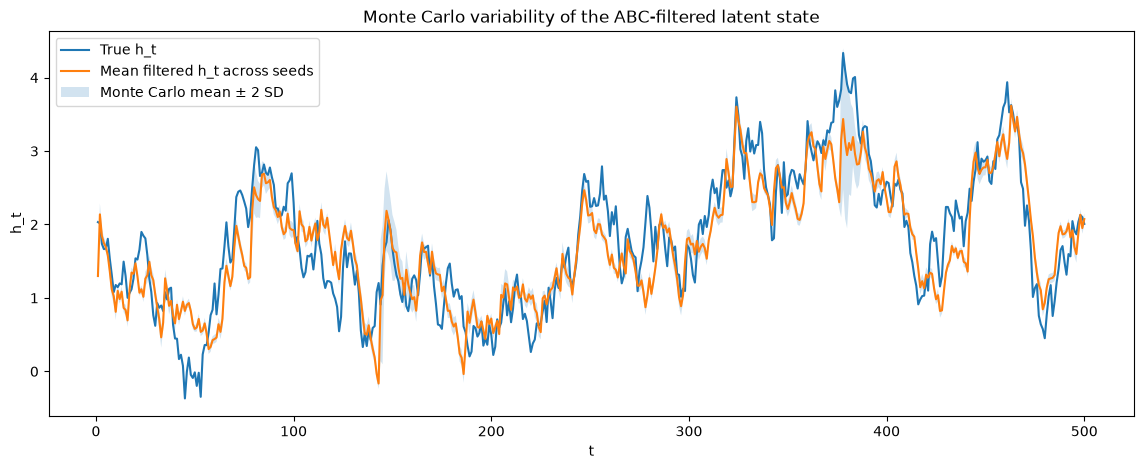

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["t"],
    true_h,
    label="True h_t",
)

plt.plot(
    df["t"],
    mc_mean_h,
    label="Mean filtered h_t across seeds",
)

plt.fill_between(
    df["t"],
    mc_mean_h - 2 * mc_sd_h,
    mc_mean_h + 2 * mc_sd_h,
    alpha=0.2,
    label="Monte Carlo mean ± 2 SD",
)

plt.xlabel("t")
plt.ylabel("h_t")
plt.title(
    "Monte Carlo variability of the ABC-filtered latent state"
)
plt.legend()

plt.show()

In [24]:
mc_metrics = []

for seed, h_hat in zip(seeds, filtered_runs):

    rmse = np.sqrt(
        np.mean(
            (true_h - h_hat) ** 2
        )
    )

    corr = np.corrcoef(
        true_h,
        h_hat
    )[0, 1]

    mc_metrics.append({
        "seed": seed,
        "rmse": rmse,
        "correlation": corr,
    })

mc_metrics = pd.DataFrame(mc_metrics)

mc_metrics

,seed,rmse,correlation
0,0,0.465857,0.867046
1,1,0.444692,0.880618
2,2,0.432633,0.883575
3,3,0.439148,0.880625
4,4,0.463186,0.869889
5,5,0.432939,0.883780
6,6,0.452566,0.873319
7,7,0.444222,0.880150
8,8,0.428043,0.885832
9,9,0.453977,0.874425


In [29]:
N_values = [1000, 2000, 5000, 10000, 20000]
max_seeds = 20

true_h = df["h"].to_numpy()

correlation_records = []

for N in N_values:

    print(f"\nN = {N}")

    correlations = []

    # Compute 20 seeds once
    for seed in range(max_seeds):

        print(f"  seed {seed + 1}/{max_seeds}", end="\r")

        result_mc = abc_filter(
            y=y,
            theta=theta_true,
            n_particles=N,
            dist="normal",
            seed=seed,
        )

        h_hat = (
            result_mc["diagnostics"]
            ["filtered_h_mean"]
            .to_numpy()
        )

        corr = np.corrcoef(
            true_h,
            h_hat
        )[0, 1]

        correlations.append(corr)

    print(f"  completed {max_seeds} seeds")

    # Summary using the first 10 and all 20 seeds
    for n_seeds in [10, 20]:

        corr_subset = np.array(
            correlations[:n_seeds]
        )

        correlation_records.append({
            "N": N,
            "n_seeds": n_seeds,
            "mean_correlation": corr_subset.mean(),
            "sd_correlation": corr_subset.std(ddof=1),
            "min_correlation": corr_subset.min(),
            "max_correlation": corr_subset.max(),
        })


correlation_results = pd.DataFrame(
    correlation_records
)

correlation_results


N = 1000
  completed 20 seeds

N = 2000
  completed 20 seeds

N = 5000
  completed 20 seeds

N = 10000
  completed 20 seeds

N = 20000
  completed 20 seeds


,N,n_seeds,mean_correlation,sd_correlation,min_correlation,max_correlation
0,1000,10,0.868446,0.009076,0.854266,0.878627
1,1000,20,0.870481,0.009121,0.854266,0.887331
2,2000,10,0.870096,0.006829,0.858042,0.881101
3,2000,20,0.871331,0.006850,0.858042,0.885915
4,5000,10,0.877926,0.006365,0.867046,0.885832
5,5000,20,0.879848,0.006434,0.867046,0.890559
6,10000,10,0.886064,0.003236,0.879373,0.889891
7,10000,20,0.885542,0.002796,0.879373,0.889891
8,20000,10,0.885051,0.002063,0.882594,0.888988
9,20000,20,0.885548,0.002318,0.881168,0.888988


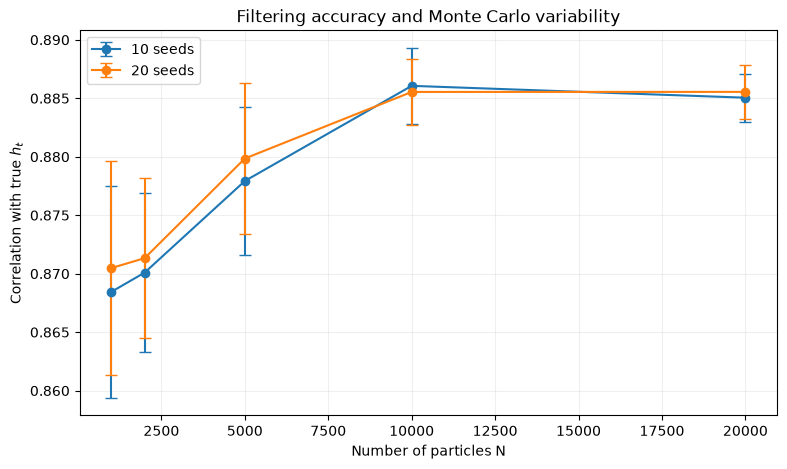

In [30]:
plt.figure(figsize=(9, 5))

for n_seeds in [10, 20]:

    subset = correlation_results[
        correlation_results["n_seeds"] == n_seeds
    ]

    plt.errorbar(
        subset["N"],
        subset["mean_correlation"],
        yerr=subset["sd_correlation"],
        marker="o",
        capsize=4,
        label=f"{n_seeds} seeds",
    )

plt.xlabel("Number of particles N")
plt.ylabel("Correlation with true $h_t$")
plt.title(
    "Filtering accuracy and Monte Carlo variability"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

### Conclusion

The ABC filter shows good and increasingly stable recovery of the latent log-volatility as the number of particles increases.

The mean correlation between the filtered estimate $\hat h_t$ and the true simulated latent state $h_t$ rises from approximately $0.87$ for small particle populations to about $0.886$ for $N=10{,}000$.

Beyond $N=10{,}000$, the filtering accuracy reaches a clear plateau: increasing the particle population to $N=20{,}000$ produces almost no further improvement in mean correlation.

At the same time, the error bars, representing one Monte Carlo standard deviation across random seeds, become smaller as $N$ increases. This indicates that larger particle populations mainly improve the numerical stability and reproducibility of the filter once the accuracy plateau has been reached.

The results obtained with 10 and 20 seeds are also very similar, suggesting that 10 Monte Carlo repetitions are already sufficient to characterize the filtering performance in this experiment.
